# Thymio Navigation Project: Report

**Course:** MICRO-452 &nbsp;|&nbsp; **Group:** 44 &nbsp;|&nbsp; **Date:** *(date)*

> **How to use this notebook.** Everything marked ✏️ is a space for you to fill in.
> Keep each section short: do **not** re-describe the code (it should be readable on its own), explain what is
> **not** in the code: theory, choices, measurements, parameters, sources.
> Run the notebook from the **project root** (the folder containing `controle/`, `filtre/`, `planification/`, `vision/`).

## Contents
0. [Group members and tasks](#0.-Group-members-and-tasks)
1. [Introduction: environment and choices](#1.-Introduction:-environment-and-choices)
2. [Module implementation](#2.-Module-implementation)
   - 2.1 [Vision](#2.1-Vision-(P1))
   - 2.2 [Filtering](#2.2-Filtering-(P2))
   - 2.3 [Global navigation](#2.3-Global-navigation-(P3))
   - 2.4 [Control and local avoidance](#2.4-Control-and-local-avoidance-(P4))
3. [Running the whole project](#3.-Running-the-whole-project)
4. [Conclusion](#4.-Conclusion)
5. [References](#5.-References)

In [1]:
import os, sys
from pathlib import Path

# Project root = the folder that contains interfaces.py
ROOT = Path.cwd().resolve()
if not (ROOT / "interfaces.py").exists():     # we are in notebooks/
    ROOT = ROOT.parent

os.chdir(ROOT)                  # relative paths (data/..., python -m controle.main) now work
sys.path.insert(0, str(ROOT))   # so `controle`, `filtre`, `planification`, `vision`, `interfaces` import

%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

---
## 0. Group members and tasks

| Member | Module | Main tasks | Files |
|---|---|---|---|
| Sujith | P1: Vision | *Camera, ArUco/QR detection, pixel → world conversion, obstacle and goal detection, measurement noise* | `vision/` |
| Matéo | P2: Filtering | *Kalman filter, noise model, kidnapping detection* | `filtre/` |
| Robin | P3: Global navigation | *Inflation of obstacles, visibility graph, Dijkstra, replanning* | `planification/` |
| Matthieu | P4: Control | *Path following, local avoidance with IR sensors, Thymio interface, calibration* | `controle/` |

> ✏️ *Check names, roles and files (the table above comes from `CONTRAT_INTERFACES.md`). Add a line on who did the
> integration (`controle/main.py`), the tests, and this report.*

---
## 1. Introduction: environment and choices

### 1.1 The task and the environment

The objective of this project is to develop an autonomous navigation system for a Thymio robot, enabling it to navigate from an arbitrary initial position within a predefined environment to a target location that can be placed anywhere in the available space.

The experimental environment consists of a **1 m × 1 m flat surface**, surrounded by black borders and containing several black polygonal obstacles. These obstacles represent forbidden areas that the robot must avoid while navigating towards its destination. The remaining white surface represents the accessible area in which the robot can move freely.

To provide the robot with information about its surroundings, a camera is mounted above the experimental setup, allowing it to observe the entire environment. An ArUco marker attached to the top of the Thymio serves as a visual reference for detecting and estimating the robot's position and orientation. Through image processing, the camera also identifies the boundaries of the environment, the obstacles and the target location.

This external vision system provides an estimate of the robot's pose and a representation of its surroundings, which can then be used by the planification and control modules. Based on this information, the robot must determine a suitable path towards the target while avoiding obstacles and remaining within the boundaries of the environment.

### 1.2 Overall architecture
The modules never import each other: they only exchange the dataclasses defined in `interfaces.py`.

| # | Flow | Message |
|---|---|---|
| 1 | Vision → Filter | `PoseMeasurement` |
| 2 | Control → Filter | `ControlInput` |
| 3 | Filter → Planning, Control | `PoseEstimate` |
| 4 | Vision → Planning | `Environment` |
| 5 | Planning → Control | `Path` |

`controle/main.py` is the main loop: every Ts = 0.1 s it reads the robot, updates the filter, asks for a path when needed,
follows the path (or avoids an obstacle) and sends the wheel speeds.

![architecture](../docs/figures/architecture_block_diagram.png)

### 1.3 Global conventions
- **World frame:** origin = bottom-left corner of the black boundary, x to the right, y up, θ counter-clockwise, θ = 0 when the robot faces +x.
- **Units:** mm, rad in [−π, π], mm/s, rad/s, s. No pixels outside Vision, no raw Thymio units outside Control.
- **Time:** `time.monotonic()`; each message carries the **capture** instant `t`. Filter step Ts = 0.1 s.

### 1.4 Calibration and key parameters
| Parameter | Value | Method | Responsible |
|---|---|---|---|
| Thymio unit → mm/s | 0.337 mm/s per unit | straight line at 227 units, ruler | Matéo + Matthieu |
| Wheelbase L | 96.5 mm | in-place rotation, angle measured on a photo | Matthieu |
| σ_v, σ_ω (command noise) | ≈ 3.6 mm/s, ≈ 0.075 rad/s | std of measured wheel speeds | Matéo |
| Ts | 0.1 s | loop measured at 101–105 ms | all |
| Camera noise σx, σy, σθ | ✏️ | ✏️ | Sujith |
| Margin | 100mm | ✏️ | Robin + Matthieu |

> ✏️ *Complete the empty rows and keep this table in sync with the "calibration log" in `CONTRAT_INTERFACES.md`.*

---
## 2. Module implementation

Each subsection has the same structure: **(a)** theory and choices, **(b)** measurements and parameters,
**(c)** the code (imported from the `.py` file, not pasted), **(d)** a demo that runs the module *independently*
(simulation or pre-recorded data), **(e)** limits.

### 2.1 Vision (P1)
*Author: Sujith*

**(a) Theory and choices**
> ✏️ *Camera model and pixel → world conversion (homography?). ArUco/QR detection method and why. How the
> obstacles and the goal are detected. How the arena corners / origin are found. Sources.*

**(b) Measurements and parameters**
> ✏️ *Measurement noise (std of x, y, θ over ~200 images with the robot still), detection rate, latency, lighting conditions...*

**(c) Code**

In [ ]:
# TODO Import and show how to use the vision module on its own
# from vision.realtime import RealCamera

**(d) Demo**
> ✏️ *Show the detection on a pre-recorded image/video (annotated image, detected pose, obstacles in the world frame).*

**(e) Limits**
> ✏️

### 2.2 Filtering (P2)
*Author: Matéo*

**(a) Theory and choices**
> ✏️ *State vector and motion model (unicycle, v and ω from the wheel speeds), Kalman filter equations (EKF?),
> how Q and R are chosen, prediction-only when the QR is hidden, kidnapping detection (test on the innovation?), Sources.*

**(b) Measurements and parameters**
> ✏️ *σ_v, σ_ω, camera noise, Q floor, detection threshold, loss-of-measurement threshold (5 s?) ...*

**(c) Code**

In [ ]:
# TODO: import and show how to use the filter on its own
# from filtre.filter_node import FilterNode

**(d) Demo**
> ✏️ *Run the filter on pre-recorded or simulated data and plot: raw camera measurement vs filtered estimate vs
> ground truth, the covariance growing when the QR is hidden, the kidnapping detection.*

**(e) Limits**
> ✏️

### 2.3 Global navigation (P3)
*Author: Robin*

**(a) Theory and choices**

The objective of the path-planning module is to determine the shortest collision-free path between the robot's current position and its target, while ensuring that the robot maintains a minimum clearance from obstacles. Since the environment is represented by a polygonal map, we use a geometric path-planning approach based on configuration space and visibility graphs.

**Configuration space and obstacle inflation**

A first difficulty in path planning is that the robot has a physical size and therefore cannot be modelled as a point moving freely through the environment. To simplify the problem, we use the concept of configuration space, in which the robot is represented by a disc and the obstacles are expanded accordingly. This operation corresponds to a Minkowski sum between each obstacle and a disc representing the robot's radius (LaValle, 2006).

In our implementation, the obstacles are inflated by a distance defined by the `margin` parameter. This distance must account for the robot's physical dimensions and the desired safety clearance. The resulting rounded obstacle boundaries are approximated by circumscribed polygons, with their resolution controlled by the `arc_step_deg` parameter. Using a circumscribed approximation ensures that the polygon does not underestimate the inflated obstacle boundary.

The outer black boundary of the environment is treated in the same way as an obstacle. Consequently, instead of inflating this boundary, the accessible area is shrunk by the margin. This ensures that the robot remains entirely within the experimental setup. After this transformation, the robot can be treated as a point, and path planning can be performed directly in the remaining free space.

**Visibility graph construction**

Once the configuration space has been defined, we construct a visibility graph to represent the possible paths through the environment. The graph consists of nodes corresponding to the corners of the inflated obstacles, as well as the robot's starting position and the target. Two nodes are connected if the straight-line segment joining them does not intersect any obstacle. Each edge is assigned a weight corresponding to its Euclidean length.

The main advantage of this approach comes from a geometric property of shortest paths in polygonal environments: an optimal collision-free path consists of straight-line segments, with changes in direction occurring at obstacle vertices. Therefore, it is sufficient to consider paths passing through the obstacle corners rather than exploring every possible position in the environment (de Berg et al., 2008).

**Shortest-path search**

After constructing the visibility graph, we use Dijkstra's algorithm to determine the minimum-distance path between the starting position and the target. The algorithm progressively explores the graph, keeping track of the minimum known distance from the starting node to every other reachable node.

We also considered A* as an alternative. However, our environment contains a relatively small number of obstacles, resulting in a visibility graph with only a few dozen nodes. In this situation, the main computational cost comes from constructing the graph and checking visibility between node pairs, rather than searching through the graph itself. Consequently, using Dijkstra provides a simple and reliable solution without requiring an additional heuristic. Although A* could reduce the number of explored nodes, we do not expect this to provide a significant performance improvement for our relatively small graph.

**Choice of representation and computational efficiency**

Another possible approach would be to discretise the environment into a regular grid and search for a path between neighbouring cells. However, this introduces a trade-off between spatial resolution and computational efficiency. A coarse grid can produce inaccurate paths, restrict the possible directions of movement and potentially miss narrow passages. Conversely, a fine grid provides a better representation of the environment but considerably increases the number of cells to explore. It can also produce unnecessarily long paths due to the discretisation of movement directions.

Furthermore, rebuilding the complete visibility graph every time the robot moves or receives a new target would introduce unnecessary computational overhead. Since the obstacles remain unchanged during the experiment, we compute the visibility graph between obstacle vertices only once and store it for subsequent use. During replanning, only the starting and target positions change, so we simply calculate their visibility connections to the existing graph before running Dijkstra again. This allows us to efficiently generate new paths without repeating the entire graph-construction process.

**Path simplification**

Finally, the path returned by Dijkstra can contain intermediate waypoints that do not correspond to actual changes in direction. For example, several consecutive waypoints may lie on the same straight line. These unnecessary points are removed through a path-simplification procedure, which checks whether consecutive segments can be replaced by a single direct segment.

Importantly, simplification is only performed when the resulting segment remains collision-free in configuration space. This preserves the required safety margin while reducing the number of waypoints the robot needs to follow. The resulting path is therefore shorter in terms of waypoints and avoids unnecessary direction changes, making it more suitable for the robot's motion controller.

**(b) Parameters**
> ✏️ *Margin (robot radius + safety, agreed with Matthieu), `arc_step_deg` and the overshoot it causes (1/cos(step/2)), computation time measured on the real map.*

**(c) Code**: `planification/global_navigation.py` (class `GlobalPlanner`)

In [2]:
from interfaces import Environment, PoseEstimate
from planification.global_navigation import GlobalPlanner

help(GlobalPlanner)

Help on class GlobalPlanner in module planification.global_navigation:

class GlobalPlanner(builtins.object)
 |  GlobalPlanner(margin_mm: 'float' = 100.0, arc_step_deg: 'float' = 45.0)
 |  
 |  Visibility graph + Dijkstra.
 |  
 |  margin_mm : robot radius + safety.
 |  The static graph (corner <-> corner) is rebuilt only when set_environment()
 |  is called, so replanning after a kidnapping only costs start/goal edges.
 |  
 |  Methods defined here:
 |  
 |  __init__(self, margin_mm: 'float' = 100.0, arc_step_deg: 'float' = 45.0)
 |      Initialize self.  See help(type(self)) for accurate signature.
 |  
 |  plan(self, pose: 'PoseEstimate', goal: 'Optional[Point]' = None) -> 'Path'
 |      Returns Path(valid=False) if no path exists (P4 then does not move).
 |      `goal` defaults to the one given by Vision in Environment.goal.
 |  
 |  set_environment(self, env: 'Environment') -> 'None'
 |      # ---- environment ----------------------------------------------------
 |  
 |  ---------

**(d) Demo** (hand-defined scene, independent of the other modules; edit the scene freely)

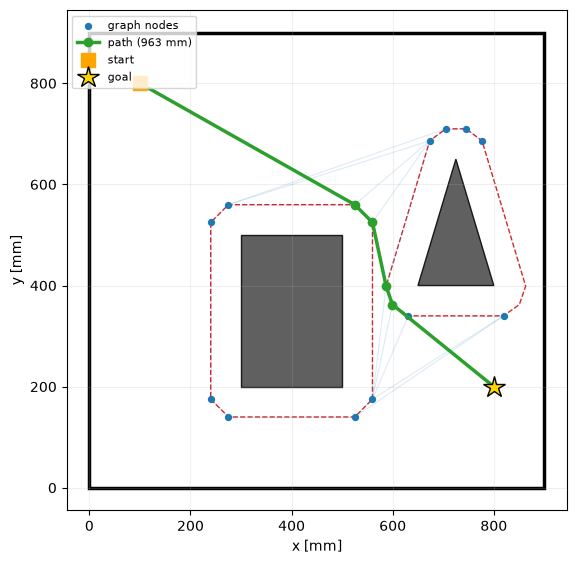

valid: True | waypoints: [(100, 800), (525, 560), (560, 525), (587, 399), (599, 362), (800, 200)]


In [ ]:
import math
from matplotlib.patches import Polygon as MplPolygon, Rectangle

# --- scene (mm, world frame: origin bottom-left of the black boundary) ---
WIDTH, HEIGHT = 900, 900
OBSTACLES = [
    [(300, 200), (500, 200), (500, 500), (300, 500)],      # rectangle
    [(650, 400), (800, 400), (725, 650)],                  # triangle
]
START, GOAL = (100, 800), (800, 200)
MARGIN_MM, ARC_STEP_DEG = 60, 45

env = Environment(t=0.0, width_mm=WIDTH, height_mm=HEIGHT, obstacles=OBSTACLES, goal=GOAL)
planner = GlobalPlanner(margin_mm=MARGIN_MM, arc_step_deg=ARC_STEP_DEG)
planner.set_environment(env)
pose = PoseEstimate(t=0.0, x=START[0], y=START[1], theta=0.0, P=np.eye(3), measurement_used=True)
path = planner.plan(pose)

# --- plot ---
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.add_patch(Rectangle((0, 0), WIDTH, HEIGHT, fill=False, edgecolor="black", linewidth=2.5))
for poly in OBSTACLES:
    ax.add_patch(MplPolygon(poly, facecolor="#444", edgecolor="black", alpha=0.85))
for poly in planner.polys:
    ax.add_patch(MplPolygon(poly, fill=False, edgecolor="tab:red", linestyle="--"))
for i, nbrs in planner.adj.items():
    for j, _ in nbrs:
        if j > i:
            a, b = planner.nodes[i], planner.nodes[j]
            ax.plot([a[0], b[0]], [a[1], b[1]], color="tab:blue", alpha=0.15, lw=0.8)
xs, ys = zip(*planner.nodes)
ax.scatter(xs, ys, s=18, color="tab:blue", zorder=3, label="graph nodes")
if path.valid:
    px, py = zip(*path.waypoints)
    length = sum(math.dist(a, b) for a, b in zip(path.waypoints, path.waypoints[1:]))
    ax.plot(px, py, "-o", color="tab:green", lw=2.5, zorder=4, label=f"path ({length:.0f} mm)")
ax.plot(*START, "s", color="orange", ms=10, zorder=5, label="start")
ax.plot(*GOAL, "*", color="gold", mec="black", ms=16, zorder=5, label="goal")
ax.set_aspect("equal"); ax.set_xlabel("x [mm]"); ax.set_ylabel("y [mm]")
ax.legend(loc="upper left", fontsize=8); ax.grid(alpha=0.2)
plt.show()
print("valid:", path.valid, "| waypoints:", [(round(x), round(y)) for x, y in path.waypoints])

**(e) Limits**
> ✏️ *Examples: the inflation is exact for convex obstacles only (use a library buffer for concave ones); the planner ignores the covariance P; the robot is modelled as a disc; static map (obstacles unseen by the camera are handled by the local avoidance).*

### 2.4 Control and local avoidance (P4)
*Author: Matthieu*

**(a) Theory and choices**
> ✏️ *Path-following law (pure pursuit? proportional on heading error?), waypoint acceptance radius, conversion
> (v, ω) → wheel speeds, local avoidance with the infrared sensors (state machine), lifted-robot (kidnapping) detection with the ground sensors, Sources.*

**(b) Measurements and parameters**
> ✏️ *Speed conversion factor, wheelbase L, IR thresholds, gains, speeds, loop timing...*

**(c) Code**

In [ ]:
# TODO: import and show the controller on its own
# from controle import controller, local_avoidance, thymio

**(d) Demo**
> ✏️ *Simulate the controller alone (`controle/simulator.py`) on a given path and plot the trajectory; show the avoidance of an unexpected obstacle.*

**(e) Limits**
> ✏️

---
## 3. Running the whole project

This section runs the complete loop on the rhymio robot. The same loop runs on the simulation (from the project root):
```
python -m controle.main --reel --goal 400 100 --plot data/real_run.png          # real robot with the camera
python -m controle.main --sim --plot data/main.png                              # simulation
```

In [ ]:
import os
from IPython.display import Image, display

os.makedirs("data", exist_ok=True)

# Real robot with the camera (same as `--reel` in the terminal)
!python -m controle.main --reel --goal 400 100 --plot data/real_run.png

display(Image("data/real_run.png"))

t=  0.0s  nouveau chemin : 2 points
t=  2.1s  obstacle -> évitement
t=  4.6s  obstacle dépassé -> nouveau chemin
t=  4.7s  nouveau chemin : 2 points
t=  8.1s  robot soulevé -> arrêt
t= 10.1s  robot reposé -> nouveau filtre (repart de la caméra) et nouveau chemin
t= 10.1s  nouveau chemin : 4 points
t= 17.6s  arrivé
final distance to goal: 15 mm | collision: False


> ✏️ *A discuter : On explique la boucle main ? On run le vrai robot ou la simulation ?*

---
## 4. Conclusion

> ✏️ *What works, what does not, and the limits observed on the real robot. Main difficulties (communication delay,
> camera noise, calibration...). What we would improve with more time (e.g. re-plan using the filter uncertainty, dynamic
> obstacles, a smoother path). What each member learned / the teamwork.*

---
## 5. References

- LaValle, S. M. (2006). Planning Algorithms, Cambridge University Press. Particularly Chapter 4 (Configuration Space) and Chapter 5 (Sampling-Based Motion Planning). Online version.
- de Berg, M., Cheong, O., van Kreveld, M., & Overmars, M. (2008). Computational Geometry: Algorithms and Applications, 3rd edition, Springer. Chapter 15 (Visibility Graphs).

> ✏️ *Cite every source used (course material, papers, library documentation). Examples of the type of source to cite:*
> - *Course notes (filtering, path planning, local navigation).*
> - *Visibility graph: de Berg et al., "Computational Geometry: Algorithms and Applications", Springer.*
> - *Dijkstra, E. W. (1959). A note on two problems in connexion with graphs. Numerische Mathematik.*
> - *OpenCV ArUco documentation.*
> - *Thymio documentation (aseba / tdmclient).*